# NB26 — Target Transformations: Log, Box–Cox and Back-Transforming

> **StatQuest principle: if the effect is a percentage, model it on a log scale.**

---

## The main ideas are:

1. Prices, incomes and counts are often **right-skewed** with effects that are **multiplicative** ("+0.8% per m²", not "+$X per m²")
2. Fitting **log(y)** turns multiplicative effects into additive ones and often fixes skewed, funnel-shaped residuals
3. Each log form has its own interpretation: **log-level, level-log, log-log (elasticity)**
4. **Box–Cox** searches for the best power transform λ (λ = 0 means log)
5. Back on the original scale, **exp(prediction) is a median, not a mean** → correct it with **Duan's smearing estimator**


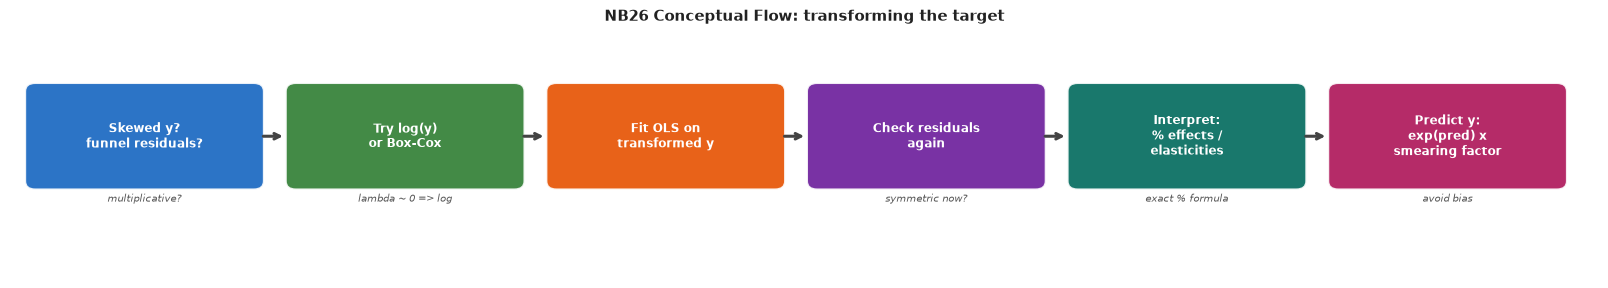

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=['Skewed y?\nfunnel residuals?', 'Try log(y)\nor Box-Cox', 'Fit OLS on\ntransformed y', 'Check residuals\nagain',
           'Interpret:\n% effects /\nelasticities', 'Predict y:\nexp(pred) x\nsmearing factor'],
    title='NB26 Conceptual Flow: transforming the target',
    notes=['multiplicative?', 'lambda ~ 0 => log', '', 'symmetric now?', 'exact % formula', 'avoid bias'],
    figsize=(16, 2.8),
)


## Step 1 — A right-skewed target: house price vs size

True model (multiplicative):  log(price) = 10 + 0.008·size + ε,  ε ~ N(0, 0.35²),  size in m².

We fit both a **level-level** model (price ~ size) and a **log-level** model (log(price) ~ size) and compare the residuals.


level-level  price ~ size      residual skew =  1.130   Shapiro p = 2.36e-10   Breusch-Pagan p = 7.11e-07
log-level  log(price) ~ size   residual skew = -0.016   Shapiro p = 5.57e-01   Breusch-Pagan p = 3.45e-01


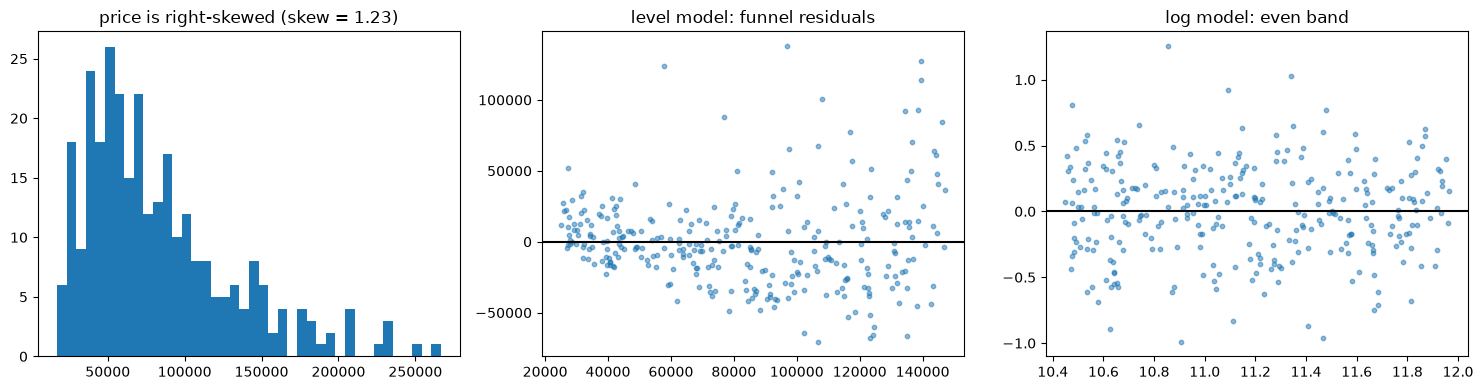

In [2]:
import numpy as np
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

rng   = np.random.default_rng(11)
n     = 300
size  = rng.uniform(50, 250, n)
price = np.exp(10 + 0.008 * size + rng.normal(0, 0.35, n))
X     = sm.add_constant(size)

lvl = sm.OLS(price, X).fit()
lg  = sm.OLS(np.log(price), X).fit()

from statsmodels.stats.diagnostic import het_breuschpagan
for name, r in [('level-level  price ~ size', lvl), ('log-level  log(price) ~ size', lg)]:
    print(f"{name:30s} residual skew = {stats.skew(r.resid):6.3f}   "
          f"Shapiro p = {stats.shapiro(r.resid).pvalue:.2e}   "
          f"Breusch-Pagan p = {het_breuschpagan(r.resid, X)[1]:.2e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(price, 40); ax[0].set_title(f'price is right-skewed (skew = {stats.skew(price):.2f})')
ax[1].scatter(lvl.fittedvalues, lvl.resid, s=10, alpha=0.5); ax[1].axhline(0, color='k')
ax[1].set_title('level model: funnel residuals')
ax[2].scatter(lg.fittedvalues, lg.resid, s=10, alpha=0.5); ax[2].axhline(0, color='k')
ax[2].set_title('log model: even band')
plt.tight_layout(); plt.show()


## Step 2 — Interpreting log coefficients (exactly)

| Model | Equation | Meaning of b |
|---|---|---|
| level-level | y = a + b·x | +1 unit of x → **+b units** of y |
| **log-level** | ln y = a + b·x | +1 unit of x → y changes by **100·(eᵇ − 1)%** (≈ 100·b% when b is small) |
| level-log | y = a + b·ln x | +1% in x → y changes by ≈ **b/100 units** (exactly b·ln 1.01) |
| **log-log** | ln y = a + b·ln x | +1% in x → y changes by ≈ **b%** — the **elasticity** (exactly 100·(1.01ᵇ − 1)%) |

The "≈ 100·b%" shortcut breaks down for large b — e.g. a dummy with b = 0.15 means **+16.18%**, not +15%.


In [3]:
b = lg.params[1]
print(f"log-level slope b = {b:.5f}")
print(f"  +1 m^2  -> price x e^b       = +{100*(np.exp(b)-1):.3f}%   (shortcut 100*b = {100*b:.3f}%)")
print(f"  +10 m^2 -> price x e^(10b)   = +{100*(np.exp(10*b)-1):.2f}%  (shortcut 1000*b = {1000*b:.2f}%)")
print()
for coef in [0.05, 0.15, 0.50]:
    print(f"dummy coefficient {coef:.2f}: exact effect = +{100*(np.exp(coef)-1):.2f}%  vs shortcut +{100*coef:.0f}%")


log-level slope b = 0.00768
  +1 m^2  -> price x e^b       = +0.771%   (shortcut 100*b = 0.768%)
  +10 m^2 -> price x e^(10b)   = +7.98%  (shortcut 1000*b = 7.68%)

dummy coefficient 0.05: exact effect = +5.13%  vs shortcut +5%
dummy coefficient 0.15: exact effect = +16.18%  vs shortcut +15%
dummy coefficient 0.50: exact effect = +64.87%  vs shortcut +50%


log-log elasticity = -1.4938  (95% CI [-1.5251, -1.4624], true -1.5)
  +1% price  -> quantity -1.475%
  +10% price -> quantity -13.27%   (not simply 10 x -1.49%)


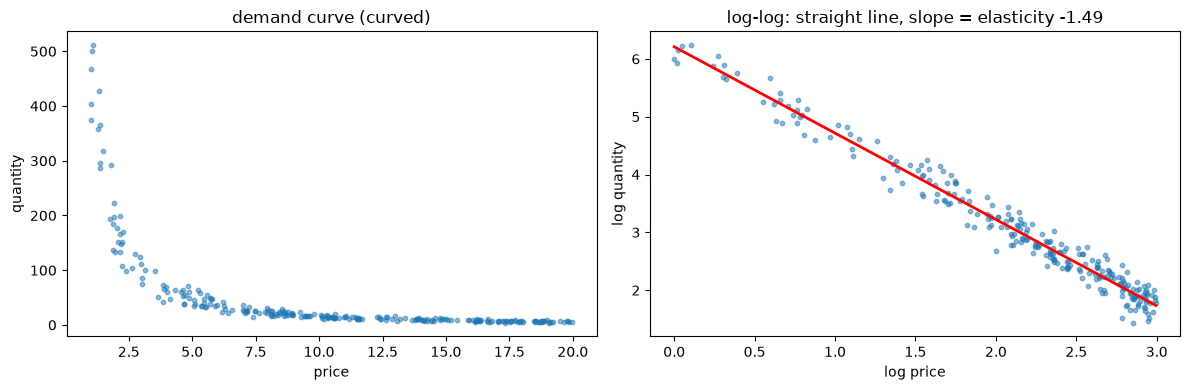

In [4]:
# log-log: price elasticity of demand
rng_d = np.random.default_rng(5)
p     = rng_d.uniform(1, 20, 250)                         # price
q     = 500 * p ** (-1.5) * np.exp(rng_d.normal(0, 0.2, 250))  # quantity, true elasticity -1.5
ll    = sm.OLS(np.log(q), sm.add_constant(np.log(p))).fit()
e     = ll.params[1]
lo, hi = ll.conf_int()[1]
print(f"log-log elasticity = {e:.4f}  (95% CI [{lo:.4f}, {hi:.4f}], true -1.5)")
print(f"  +1% price  -> quantity {100*(1.01**e - 1):.3f}%")
print(f"  +10% price -> quantity {100*(1.10**e - 1):.2f}%   (not simply 10 x {e:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(p, q, s=10, alpha=0.5); ax[0].set_title('demand curve (curved)'); ax[0].set_xlabel('price'); ax[0].set_ylabel('quantity')
ax[1].scatter(np.log(p), np.log(q), s=10, alpha=0.5)
xx = np.linspace(np.log(p).min(), np.log(p).max(), 50); ax[1].plot(xx, ll.params[0] + e*xx, 'r', lw=2)
ax[1].set_title(f'log-log: straight line, slope = elasticity {e:.2f}'); ax[1].set_xlabel('log price'); ax[1].set_ylabel('log quantity')
plt.tight_layout(); plt.show()


## Step 3 — Box–Cox: let the data choose the transform

```
y(λ) = (y^λ − 1) / λ     if λ ≠ 0
y(λ) = ln(y)             if λ = 0
```

`scipy.stats.boxcox` picks λ by maximum likelihood. λ ≈ 1 → no transform needed, λ ≈ 0.5 → square root, λ ≈ 0 → log.

Box–Cox needs **y > 0**. For zero/negative values use **Yeo–Johnson** (`sklearn.preprocessing.PowerTransformer`).

Note: here we apply Box–Cox to price alone (marginally). Strictly, λ should be chosen for the **residuals** of the model — `boxcox` on y is a quick first look.


Box-Cox lambda = 0.0080   (95% CI [-0.1738, 0.1902])
-> the interval contains 0, so a plain log transform is supported.


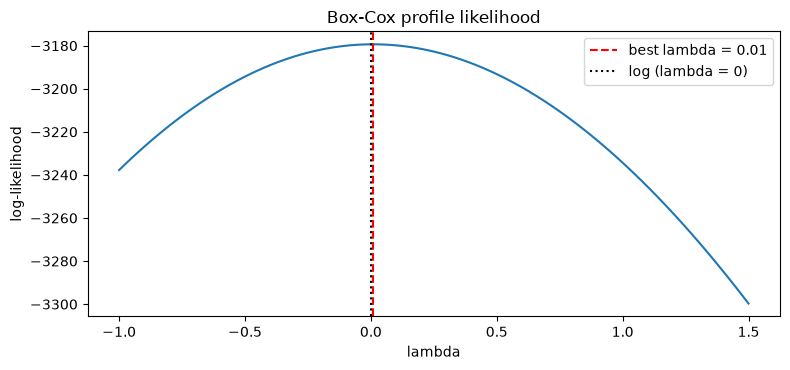

In [5]:
price_bc, lam = stats.boxcox(price)
lo, hi = stats.boxcox(price, alpha=0.05)[2]
print(f"Box-Cox lambda = {lam:.4f}   (95% CI [{lo:.4f}, {hi:.4f}])")
print("-> the interval contains 0, so a plain log transform is supported.")

lams = np.linspace(-1, 1.5, 101)
llf  = [stats.boxcox_llf(l, price) for l in lams]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lams, llf); ax.axvline(lam, color='r', ls='--', label=f'best lambda = {lam:.2f}')
ax.axvline(0, color='k', ls=':', label='log (lambda = 0)')
ax.set_xlabel('lambda'); ax.set_ylabel('log-likelihood'); ax.set_title('Box-Cox profile likelihood'); ax.legend()
plt.tight_layout(); plt.show()


## Step 4 — Back to dollars: retransformation bias and Duan's smearing

If ln y = Xb + ε, then **exp(Xb) estimates the median of y, not the mean** — because E[e^ε] > 1 (Jensen's inequality).

- If ε is normal: E[y|x] = exp(Xb) · exp(σ²/2)
- **Duan's smearing estimator** (no normality needed): E[y|x] ≈ exp(Xb) · mean(exp(eᵢ)), using the training residuals eᵢ

We fit on the 300 observed houses, then score a **large fresh sample (100,000 houses) from the same process**,
so the comparison is not swamped by the noise of a small test set.


In [6]:
fit    = sm.OLS(np.log(price), X).fit()            # fit on the 300 observed houses
rng_new = np.random.default_rng(99)
size_new  = rng_new.uniform(50, 250, 100_000)              # fresh houses from the same process
price_new = np.exp(10 + 0.008 * size_new + rng_new.normal(0, 0.35, 100_000))
X_new  = sm.add_constant(size_new)

naive  = np.exp(fit.predict(X_new))
smear  = np.mean(np.exp(fit.resid))
normal = np.exp(fit.scale / 2)
actual = price_new.mean()

print(f"Mean actual price (100,000 new houses): {actual:10,.0f}")
print(f"Mean naive exp(pred)                  : {naive.mean():10,.0f}   ({100*(naive.mean()/actual-1):+.1f}%)  <- biased low")
print(f"Duan smearing factor mean(exp(e_i))   : {smear:.4f}")
print(f"Mean smeared prediction               : {(naive*smear).mean():10,.0f}   ({100*((naive*smear).mean()/actual-1):+.1f}%)")
print(f"Normal-theory factor exp(s^2/2)       : {normal:.4f}   (true exp(0.35^2/2) = {np.exp(0.35**2/2):.4f})")


Mean actual price (100,000 new houses):     86,333
Mean naive exp(pred)                  :     80,488   (-6.8%)  <- biased low
Duan smearing factor mean(exp(e_i))   : 1.0634
Mean smeared prediction               :     85,588   (-0.9%)
Normal-theory factor exp(s^2/2)       : 1.0636   (true exp(0.35^2/2) = 1.0632)


## Key Takeaways

1. Log-transform a **positive, right-skewed** target when effects are **multiplicative** — residuals usually become symmetric and evenly spread.
2. **Interpretation:** log-level → 100·(eᵇ − 1)% per unit of x; log-log → b is an **elasticity** (% change in y per 1% change in x).
3. The "100·b %" shortcut is only accurate for small b (b = 0.15 → +16.18%, not +15%).
4. **Box–Cox** estimates the best power λ; if its CI contains 0, use the log (easier to interpret). Use **Yeo–Johnson** for y ≤ 0.
5. **exp(prediction) underestimates the mean** — multiply by Duan's smearing factor (or exp(σ²/2) under normality).
6. Compare models on the **same scale**: R² of a log model is about log(y), not y.
